# Taller: Análisis de datos con Pandas, NumPy y visualización
**Integrantes:**
1. Juan Esteban Silva Espejo
2. Michael Arles Gomez Bernal

**Fecha:** 22/10/2026

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid") # estilo de los gráficos


# ***PARTE A***

## Parte A1. Cargar y conocer un dataset


In [29]:
URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/taxis.csv"
taxis = pd.read_csv(URL)

print(taxis.shape)
taxis.info()
print("Memoria (MB):", taxis.memory_usage(deep=True).sum() / 1e6)
taxis.head()

(6433, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pickup           6433 non-null   object 
 1   dropoff          6433 non-null   object 
 2   passengers       6433 non-null   int64  
 3   distance         6433 non-null   float64
 4   fare             6433 non-null   float64
 5   tip              6433 non-null   float64
 6   tolls            6433 non-null   float64
 7   total            6433 non-null   float64
 8   color            6433 non-null   object 
 9   payment          6389 non-null   object 
 10  pickup_zone      6407 non-null   object 
 11  dropoff_zone     6388 non-null   object 
 12  pickup_borough   6407 non-null   object 
 13  dropoff_borough  6388 non-null   object 
dtypes: float64(5), int64(1), object(8)
memory usage: 703.7+ KB
Memoria (MB): 3.484516


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


## A2. Tipos de datos eficientes

In [30]:
taxis["pickup"] = pd.to_datetime(taxis["pickup"])
taxis["dropoff"] = pd.to_datetime(taxis["dropoff"])

for col in ["color", "payment", "pickup_zone", "dropoff_zone", "pickup_borough", "dropoff_borough"]:
    taxis[col] = taxis[col].astype("category")

taxis["passengers"] = pd.to_numeric(taxis["passengers"], downcast="integer")

for col in ["distance", "fare", "tip", "tolls", "total"]:
    taxis[col] = pd.to_numeric(taxis[col], downcast="float")

print(taxis.dtypes)
print("Memoria (MB):", taxis.memory_usage(deep=True).sum() / 1e6)

pickup             datetime64[ns]
dropoff            datetime64[ns]
passengers                   int8
distance                  float32
fare                      float32
tip                       float32
tolls                     float32
total                     float32
color                    category
payment                  category
pickup_zone              category
dropoff_zone             category
pickup_borough           category
dropoff_borough          category
dtype: object
Memoria (MB): 0.328913


## A3. Lectura por bloques (chunking)

In [31]:
suma_tarifas = 0
total_viajes = 0

for bloque in pd.read_csv(URL, chunksize=2000, usecols=["fare"]):
    suma_tarifas += bloque["fare"].sum()
    total_viajes += len(bloque)
    print("Bloque de", len(bloque), "filas")

print("Tarifa promedio (por bloques):", suma_tarifas / total_viajes)
print("Tarifa promedio (completo):", taxis["fare"].mean())

Bloque de 2000 filas
Bloque de 2000 filas
Bloque de 2000 filas
Bloque de 433 filas
Tarifa promedio (por bloques): 13.091072594434946
Tarifa promedio (completo): 13.091073


## A4. Limpieza de datos

In [32]:
print(taxis.isna().sum())
print("Duplicados:", taxis.duplicated().sum())
print("Viajes con distancia 0:", (taxis["distance"] == 0).sum())

limpio = taxis.dropna(subset=["payment", "pickup_borough", "dropoff_borough"])
limpio = limpio[limpio["distance"] > 0].copy()
print("Antes:", len(taxis), "| Después:", len(limpio))

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64
Duplicados: 0
Viajes con distancia 0: 51
Antes: 6433 | Después: 6309


##A5. Transformación con NumPy vectorizado

In [33]:
limpio["duracion_min"] = (limpio["dropoff"] - limpio["pickup"]).dt.total_seconds() / 60
limpio["pct_propina"] = np.where(limpio["fare"] > 0, limpio["tip"] / limpio["fare"] * 100, 0)
limpio["tipo_viaje"] = np.select(
    [limpio["distance"] < 2, limpio["distance"] < 8],
    ["corto", "medio"],
    default="largo"
)

limpio.groupby("payment", observed=True)["pct_propina"].agg(["count", "mean", "median"])

,count,mean,median
payment,,,
cash,1776,0.000000,0.000000
credit card,4533,23.848318,25.555557


## A5: prueba de velocidad


In [34]:
import time
numeros = np.random.rand(1_000_000)

inicio = time.time()
total = 0
for x in numeros:
    total += x * x
print("Ciclo:", time.time() - inicio, "s")

inicio = time.time()
total = (numeros * numeros).sum()
print("Vectorizado:", time.time() - inicio, "s")

Ciclo: 0.2955453395843506 s
Vectorizado: 0.0047643184661865234 s


## A6. Visualización exploratoria (4 ejemplos)

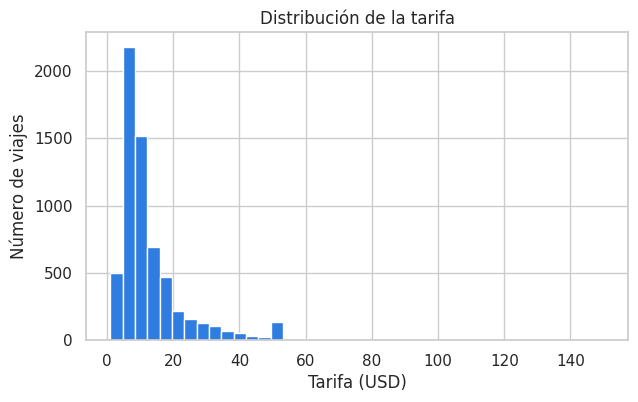

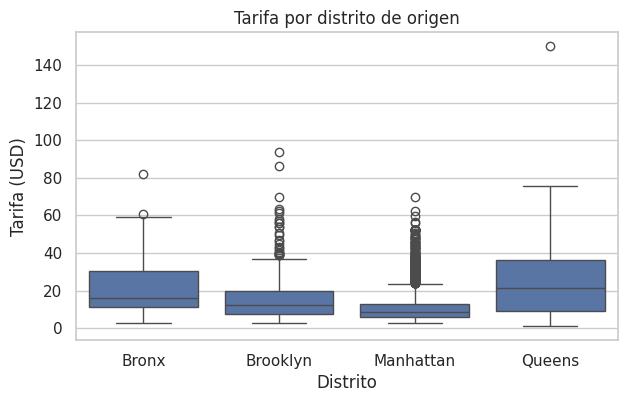

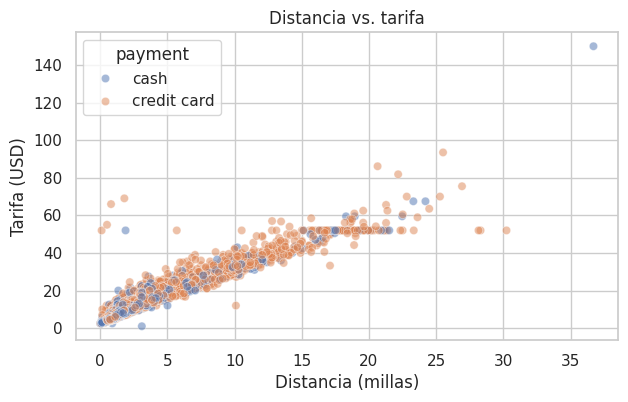

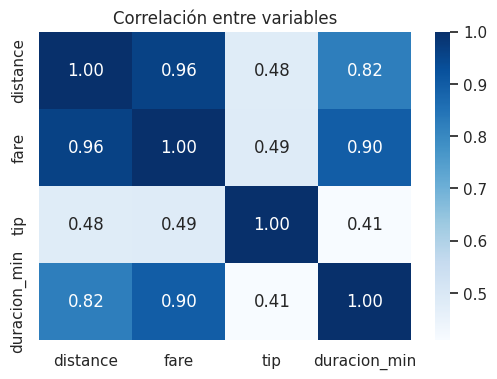

In [35]:
# Ejemplo 1: Histograma
plt.figure(figsize=(7, 4))
plt.hist(limpio["fare"], bins=40, color="#2F7DE1", edgecolor="white")
plt.title("Distribución de la tarifa")
plt.xlabel("Tarifa (USD)")
plt.ylabel("Número de viajes")
plt.show()

# Ejemplo 2: Diagrama de caja
plt.figure(figsize=(7, 4))
sns.boxplot(data=limpio, x="pickup_borough", y="fare")
plt.title("Tarifa por distrito de origen")
plt.xlabel("Distrito")
plt.ylabel("Tarifa (USD)")
plt.show()

# Ejemplo 3: Dispersión
plt.figure(figsize=(7, 4))
sns.scatterplot(data=limpio, x="distance", y="fare", hue="payment", alpha=0.5)
plt.title("Distancia vs. tarifa")
plt.xlabel("Distancia (millas)")
plt.ylabel("Tarifa (USD)")
plt.show()

# Ejemplo 4: Mapa de calor
columnas = ["distance", "fare", "tip", "duracion_min"]
plt.figure(figsize=(6, 4))
sns.heatmap(limpio[columnas].corr(), annot=True, fmt=".2f", cmap="Blues")
plt.title("Correlación entre variables")
plt.show()

# Parte B

## B1. Carga y exploración

In [36]:
URL_D = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/diamonds.csv"
diamantes = pd.read_csv(URL_D)

print("Tamaño (filas, columnas):", diamantes.shape)
print("\nInformación del DataFrame:")
diamantes.info()
mem_inicial = diamantes.memory_usage(deep=True).sum() / 1e6
print(f"\nMemoria inicial (MB): {mem_inicial:.2f} MB")
diamantes.head()

Tamaño (filas, columnas): (53940, 10)

Información del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  object 
 2   color    53940 non-null  object 
 3   clarity  53940 non-null  object 
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 4.1+ MB

Memoria inicial (MB): 11.51 MB


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


Clasificación de columnas:

*   Columnas numéricas (7): carat, depth, table,
price, x, y, z.
*   Columnas categóricas (3): cut, color, clarity.





## B2. Tipos de datos eficientes

In [37]:
mem_antes = diamantes.memory_usage(deep=True).sum() / 1e6

# 1. Replicar: Convertir numéricos a tipos más pequeños
diamantes["price"] = pd.to_numeric(diamantes["price"], downcast="integer")
for col in ["carat", "depth", "table", "x", "y", "z"]:
    diamantes[col] = pd.to_numeric(diamantes[col], downcast="float")

# 2. Ampliar: Convertir cut, color y clarity a categorías ordenadas (de peor a mejor)
orden_cut = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
orden_color = ["J", "I", "H", "G", "F", "E", "D"]
orden_clarity = ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]

diamantes["cut"] = pd.Categorical(diamantes["cut"], categories=orden_cut, ordered=True)
diamantes["color"] = pd.Categorical(diamantes["color"], categories=orden_color, ordered=True)
diamantes["clarity"] = pd.Categorical(diamantes["clarity"], categories=orden_clarity, ordered=True)

# 3. Medir memoria antes, después y porcentaje de reducción
mem_despues = diamantes.memory_usage(deep=True).sum() / 1e6
reduccion = (1 - (mem_despues / mem_antes)) * 100

print(diamantes.dtypes)
print(f"\nMemoria antes: {mem_antes:.2f} MB")
print(f"Memoria después: {mem_despues:.2f} MB")
print(f"Reducción de memoria: {reduccion:.2f}%")

carat       float32
cut        category
color      category
clarity    category
depth       float32
table       float32
price         int16
x           float32
y           float32
z           float32
dtype: object

Memoria antes: 11.51 MB
Memoria después: 1.57 MB
Reducción de memoria: 86.39%


## B3. Lectura por bloques (Chunking)

In [38]:
suma_precios = 0
total_diamantes = 0

for bloque in pd.read_csv(URL_D, chunksize=10000, usecols=["price", "carat"]):
    suma_precios += bloque["price"].sum()
    total_diamantes += len(bloque)
    print(f"Bloque procesado: {len(bloque)} filas")

print("\nPrecio promedio (por bloques):", suma_precios / total_diamantes)
print("Precio promedio (dataset completo):", diamantes["price"].mean())

Bloque procesado: 10000 filas
Bloque procesado: 10000 filas
Bloque procesado: 10000 filas
Bloque procesado: 10000 filas
Bloque procesado: 10000 filas
Bloque procesado: 3940 filas

Precio promedio (por bloques): 3932.799721913237
Precio promedio (dataset completo): 3932.799721913237


In [39]:
acumulado_cut = None

for bloque in pd.read_csv(URL_D, chunksize=10000, usecols=["cut", "price"]):
    parcial = bloque.groupby("cut")["price"].agg(["sum", "count"])
    if acumulado_cut is None:
        acumulado_cut = parcial
    else:
        acumulado_cut = acumulado_cut.add(parcial, fill_value=0)

acumulado_cut["promedio_bloques"] = acumulado_cut["sum"] / acumulado_cut["count"]
# Reordenar según calidad de corte para mostrarlo limpio
acumulado_cut = acumulado_cut.reindex(["Fair", "Good", "Very Good", "Premium", "Ideal"])
acumulado_cut

,sum,count,promedio_bloques
cut,,,
Fair,7017600,1610,4358.757764
Good,19275009,4906,3928.864452
Very Good,48107623,12082,3981.759891
Premium,63221498,13791,4584.257704
Ideal,74513487,21551,3457.541970


## B4. Limpieza


In [40]:
# 1. Revisión inicial
print("Valores nulos por columna:\n", diamantes.isna().sum())

n_inicial = len(diamantes)

# Criterio 1: Filas duplicadas
df_sin_dup = diamantes.drop_duplicates()
elim_duplicados = n_inicial - len(df_sin_dup)

# Criterio 2: Alguna dimensión igual a 0 (x, y o z == 0)
cond_cero = (df_sin_dup[["x", "y", "z"]] == 0).any(axis=1)
df_sin_ceros = df_sin_dup[~cond_cero]
elim_ceros = len(df_sin_dup) - len(df_sin_ceros)

# Criterio 3: Dimensiones absurdas (y > 20 o z > 20)
cond_absurda = (df_sin_ceros["y"] > 20) | (df_sin_ceros["z"] > 20)
diamantes_limpio = df_sin_ceros[~cond_absurda].copy()
elim_absurdas = len(df_sin_ceros) - len(diamantes_limpio)

print(f"\nFilas antes: {n_inicial} | Filas después: {len(diamantes_limpio)}")
print(f"Total eliminadas: {n_inicial - len(diamantes_limpio)}")

# Ampliar: Pequeña tabla con cada criterio y filas eliminadas
tabla_limpieza = pd.DataFrame({
    "Criterio de limpieza": [
        "Valores nulos",
        "Filas duplicadas",
        "Dimensiones iguales a 0 (x, y o z = 0)",
        "Dimensiones absurdas (y > 20 mm o z > 20 mm)",
        "TOTAL ELIMINADAS"
    ],
    "Filas eliminadas": [
        0,
        elim_duplicados,
        elim_ceros,
        elim_absurdas,
        elim_duplicados + elim_ceros + elim_absurdas
    ]
})
tabla_limpieza

Valores nulos por columna:
 carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

Filas antes: 53940 | Filas después: 53772
Total eliminadas: 168


,Criterio de limpieza,Filas eliminadas
0,Valores nulos,0
1,Filas duplicadas,146
2,"Dimensiones iguales a 0 (x, y o z = 0)",19
3,Dimensiones absurdas (y > 20 mm o z > 20 mm),3
4,TOTAL ELIMINADAS,168


## B5. Transformación vectorizada con NumPy

In [41]:
# Replicar: Crear las 4 columnas vectorizadas
diamantes_limpio["precio_quilate"] = diamantes_limpio["price"] / diamantes_limpio["carat"]
diamantes_limpio["volumen"] = diamantes_limpio["x"] * diamantes_limpio["y"] * diamantes_limpio["z"]
diamantes_limpio["rango_precio"] = np.select(
    [diamantes_limpio["price"] < 1000, diamantes_limpio["price"] < 5000],
    ["económico", "medio"],
    default="alto"
)
diamantes_limpio["log_precio"] = np.log10(diamantes_limpio["price"])

# Ampliar: Crear una variable nueva (relación largo/ancho para medir simetría)
diamantes_limpio["simetria_xy"] = diamantes_limpio["x"] / diamantes_limpio["y"]

# Mediana por tipo de corte con observed=True
resumen_corte = diamantes_limpio.groupby("cut", observed=True)[["price", "carat", "precio_quilate"]].median()
resumen_corte

,price,carat,precio_quilate
cut,,,
Fair,3282.0,1.00,3443.000000
Good,3038.0,0.82,3612.422852
Very Good,2647.0,0.71,3604.225342
Premium,3177.5,0.85,3763.333496
Ideal,1813.0,0.54,3307.272705




La nueva variable "simetria_xy (x/y)" sirve para medir como su nombre lo indica, que tan simetrica es la cara superior del diamante.

Un valos cercano a 1.0 nos demostraria un corte redondo y por ende perfectamete simetrico, mientras que valores cercanos a 0 nos demostrarian formas ovaladas o dichamente asimetricas.

## B6. Visualizaciones exploratorias

### Gráfico 1: Histograma de price y log_precio

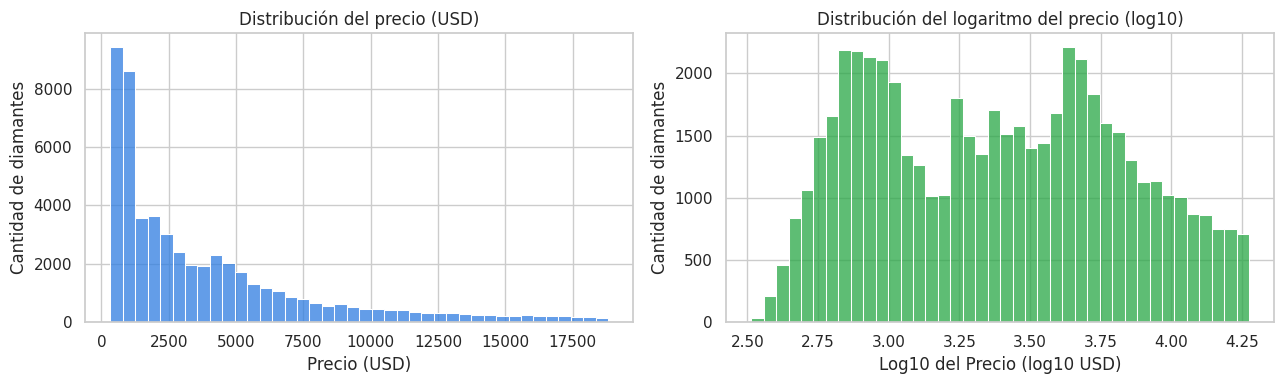

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(diamantes_limpio["price"], bins=40, color="#2F7DE1", ax=axes[0])
axes[0].set_title("Distribución del precio (USD)")
axes[0].set_xlabel("Precio (USD)")
axes[0].set_ylabel("Cantidad de diamantes")

sns.histplot(diamantes_limpio["log_precio"], bins=40, color="#28A745", ax=axes[1])
axes[1].set_title("Distribución del logaritmo del precio (log10)")
axes[1].set_xlabel("Log10 del Precio (log10 USD)")
axes[1].set_ylabel("Cantidad de diamantes")

plt.tight_layout()
plt.show()

La distribucion del precio original tiene una asimetria hacia la derecha muy fuerte, en donde concentra la mayoria de los diamantes por menos de $5.000 DLS.

Al aplicar la transformacion logaritmica, la escala se comprime y nos deja ver como la distribucion queda mucho mas equilibrada con dos picos. Alrededor de log10 = 2.9 (~ 800 DLS) y log10 = 3.6 (~ 4.000 DLS)


### Gráfico 2: Diagrama de caja de price por cut

/tmp/ipykernel_1481/3156625582.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=diamantes_limpio, x="cut", y="price", palette="Blues")


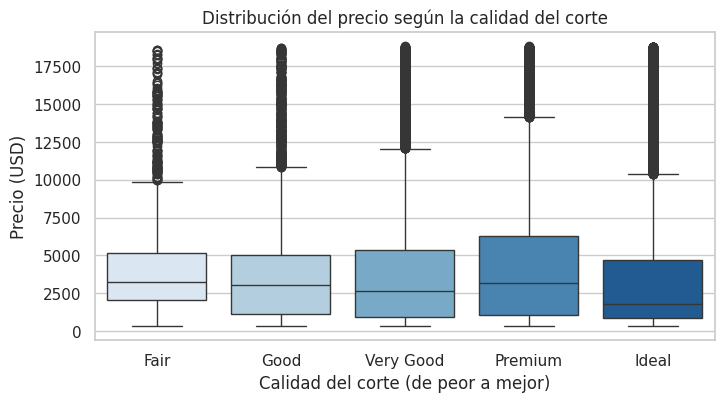

In [43]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=diamantes_limpio, x="cut", y="price", palette="Blues")
plt.title("Distribución del precio según la calidad del corte")
plt.xlabel("Calidad del corte (de peor a mejor)")
plt.ylabel("Precio (USD)")
plt.show()

El corte de mayor calidad o sea, el ideal, tiene una meduana de precio mas baja (~ 1.809 DLS), mientras que cortes inferiores como Fair o Premium muestran medianas mas altas (~ 3.282 DLS y ~ 3.182 DLS). Tambien, en todos los cortes de los diamantes, existen valores atipicos con precios de hasta $19.000 DLS

### Gráfico 3: Dispersión de carat vs. price

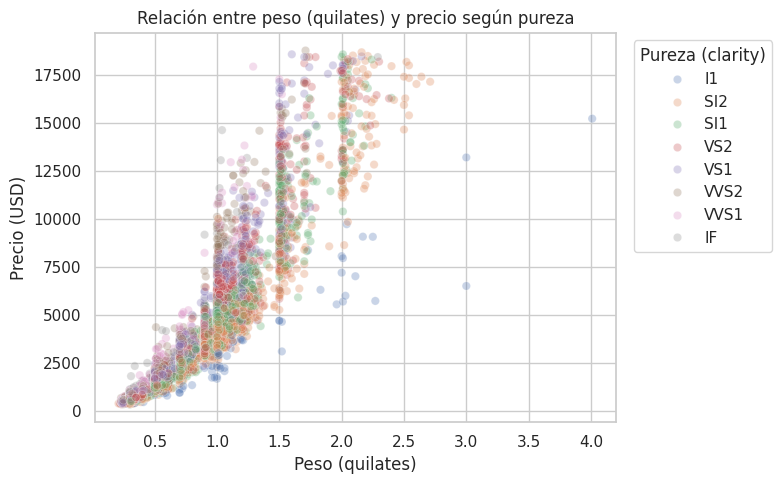

In [44]:
muestra = diamantes_limpio.sample(5000, random_state=1)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=muestra, x="carat", y="price", hue="clarity", alpha=0.3)
plt.title("Relación entre peso (quilates) y precio según pureza")
plt.xlabel("Peso (quilates)")
plt.ylabel("Precio (USD)")
plt.legend(title="Pureza (clarity)", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Existe una fuerte relacion positiva pero no exponecial respecto a el peso en quilates vs el precio del diamante. Los diamantes con mismo peso en quilates pero con mayor pureza (IF, VVS1, VVS2) esta en la franja superior de precio frente a los de menor pureza (I1, SI2).

### Gráfico 4: Mapa de calor de correlaciones

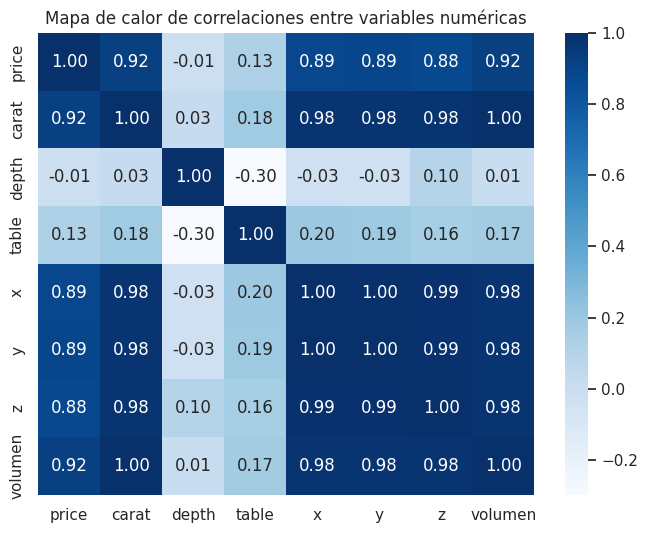

In [45]:
cols_corr = ["price", "carat", "depth", "table", "x", "y", "z", "volumen"]
plt.figure(figsize=(8, 6))
sns.heatmap(diamantes_limpio[cols_corr].corr(), annot=True, fmt=".2f", cmap="Blues")
plt.title("Mapa de calor de correlaciones entre variables numéricas")
plt.show()

Escogimos el mapa de calor porque nos muestra direcatmanete que variables determinan el precio del diamante.

El peso (carat, correlación de 0.92) y las dimensiones físicas (x, y, z, volumen, entre 0.88 y 0.92) están fuertemente correlacionados con price.

Por el contrario, depth tiene una correlación prácticamente nula (-0.01) con el precio.

# PARTE C

In [46]:
print("--- Mediana de precio y carat para diamantes entre 0.9 y 1.1 quilates por corte ---")
filtro_1ct = diamantes_limpio[(diamantes_limpio["carat"] >= 0.9) & (diamantes_limpio["carat"] <= 1.1)]
print(filtro_1ct.groupby("cut", observed=True)[["price", "carat"]].median())

print("\n--- Mediana de precio y carat por color (D vs J) ---")
print(diamantes_limpio.groupby("color", observed=True)[["price", "carat", "precio_quilate"]].median())

--- Mediana de precio y carat para diamantes entre 0.9 y 1.1 quilates por corte ---
            price  carat
cut                     
Fair       3733.0   1.00
Good       4310.5   1.00
Very Good  4690.0   1.01
Premium    4672.0   1.01
Ideal      5222.0   1.02

--- Mediana de precio y carat por color (D vs J) ---
        price  carat  precio_quilate
color                               
J      4234.5   1.11     3780.000000
I      3720.0   1.00     3775.555664
H      3447.0   0.90     3817.741943
G      2242.0   0.70     3490.384766
F      2345.0   0.70     3495.774658
E      1740.0   0.53     3256.494141
D      1842.0   0.53     3411.375000


## PARTE C. Analisis


1. *¿Qué conversión de tipo de dato redujo más la memoria y por qué?*

   La conversión de las columnas de texto (cut, color, clarity) de tipo object a category fue la que más redujo la memoria ya que bajo el total del DataFrame de 11,5 MB a 1,6 MB, aproximadamente un 86% menos.

   Buscando en internet, encontramos que el tipo object guarda un puntero y una cadena de texto completa en Python por cada una de las 53.940 filas, mientras que category guarda los textos únicos una sola vez y representa cada fila con un entero de 1 byte

2. *¿Cuántas filas eliminaron en total? Para cada criterio de limpieza, ¿era mejor eliminar o corregir? Justifiquen.*

   Se eliminaron 168 filas en total pasando de 53.940 a 53.772 registros. Encontrando 146 filas duplicadas, 20 filas con alguna dimensión igual a 0 y 2 filas con dimensiones absurdas como: y > 20 mm o z > 20 mm.

* En los duplicados era obligatorio eliminar para no inflar artificialmente el conteo.

* En las dimensiones en 0 o mayores a 20 mm, eliminar fue la mejor decisión porque representan apenas el 0,04% del dataset (22 filas de 53.940), ademas no teníamos forma confiable de saber si el error estaba en las medidas o en el quilataje

3. *Paradoja del corte: el corte «Ideal» es el mejor, pero tiene el precio mediano más bajo. ¿Por qué?*

   En todo el dataset, el corte Ideal tiene la mediana de precio más baja siendo de 1.809,50 DLS frente a Fair con 3.282,00 DLS o Premium con 3.182,00 DLS porque la variable de confusión es el peso o sea la veriable "Carat".

   La mediana de peso de los diamantes Ideal es de apenas 0,54 quilates, mientras que en Fair es de 1,00 quilate y en Premium de 0,86 quilates, asumiendo que los joyeros suelen usar cortes Ideal en piedras pequeñas para maximizar su brillo y cortes Fair/Premium en piedras más grandes para no desperdiciar peso en bruto.

   En el momento en el que aislamos solo los diamantes de tamaño similar estando entre 0,9 y 1,1 quilates, la paradoja desaparece por completo y el precio sube con la calidad del corte:
 * Fair ~ 3.990 DLS
 * Good ~ 4.588 DLS
 * Very Good ~ 4.952 DLS
 * Premium ~ 5.078 DLS
 * Ideal ~ 5.607 DLS

4. *¿Ocurre algo parecido con el color? Comparen el precio mediano del color D (el mejor) y del J (el peor), y expliquen.*

   Sí, el mejor color (D) tiene una mediana de precio de 1.838 DLS, mucho menor que la del peor color (J), cuya mediana es de 4.234 DLS.

   La explicación nuevamente está en el peso mediano o sea el "Carat" ya que los diamantes de color D pesan en mediana 0,53 quilates, mientras que los de color J pesan en mediana 1,11 quilates  casi más del doble, lo que arrastra su precio total hacia arriba.

5. *Según el mapa de calor o la correlación, ¿qué variable se relaciona más con el precio? ¿La variable depth sirve para predecir el precio?*

   La variable que más se relaciona con el precio es el peso en quilates "Carat", con una correlación lineal de 0,92 luego estando variables como el volumen y las dimensiones x, y, z, entre 0,88 y 0,90.

   En cambio, la variable "Depth" tiene una correlación de -0,01 con el precio en donde es prácticamente cero, por lo que por si sola no sirve para predecir el precio de un diamante.

6. *¿Qué forma tiene la distribución del precio? ¿Qué cambia al usar log_precio?*

   La distribución original de price es asimétrica a la derecha, en donde la gran mayoría de los diamantes cuestan menos de 3.000 DLS y una cola larga se extiende hasta casi 19.000 DLS.

   Al usar log_precio, se comprime la cola derecha, la distribución se vuelve mucho más simétrica y muestra una estructura bimodal diamantes pequeños económicos y diamantes de alrededor de 1 quilate  .

7. *¿En qué situación real de un proyecto sería indispensable leer por bloques (chunking)?*

   Sería indispensable cuando el tamaño del archivo supera la memoria RAM disponible del entorno de ejecución por ejemplo, procesar un archivo CSV de 50 GB de registros de transacciones bancarias o logs de servidores en una máquina virtual o contenedor con solo 8 GB de RAM, porque provocaria que el programa colapse por un error MemoryError.

# Parte D: Consulta y propuesta

### D1. Consulta

1. Las «4 C» de los diamantes son el estándar internacional creado por el Gemological Institute of America (GIA) para evaluar la calidad y el valor de un diamante:

* Carat (Peso en quilates): Se relaciona con la columna carat y físicamente con las dimensiones x, y, z.

* Cut (Corte o talla): Se relaciona con la columna cut y las proporciones geométricas depth y table.

* Color (Color): Se relaciona con la columna color la cual escala de ausencia de color desde D hasta J.

* Clarity (Pureza o claridad): Se relaciona con la columna clarity relacionandose con ausencia de inclusiones internas desde I1 hasta IF.

Fuente: [Gemological Institute of America (GIA) - The 4Cs of Diamond Quality](https://www.gia.edu/diamond-quality-factor)

2. Almacenamiento interno de category en Pandas: Internamente, una columna category no almacena las cadenas de texto repetidas en cada fila, sino dos estructuras separadas: un arreglo categories (un diccionario/índice con los valores únicos existentes, guardados una sola vez) y un arreglo numérico codes (enteros pequeños como int8 o int16 del mismo largo de la columna que indican qué posición del diccionario corresponde a cada fila). Ocupa mucha menos memoria porque reemplaza miles de objetos string pesados en memoria por enteros de 1 byte.

Fuente: [Pandas Official Documentation - Categorical data](https://pandas.pydata.org/docs/user_guide/categorical.html)

### D2. Propuesta

In [47]:
# Calcular cuartiles y rango intercuartílico (IQR) de precio_quilate por corte y pureza
stats_grupo = diamantes_limpio.groupby(["cut", "clarity"], observed=True)["precio_quilate"].agg(
    Q1=lambda x: np.percentile(x, 25),
    mediana="median",
    Q3=lambda x: np.percentile(x, 75)
).reset_index()

stats_grupo["IQR"] = stats_grupo["Q3"] - stats_grupo["Q1"]
stats_grupo["limite_bajo"] = stats_grupo["Q1"] - 1.5 * stats_grupo["IQR"]
stats_grupo["limite_alto"] = stats_grupo["Q3"] + 1.5 * stats_grupo["IQR"]

# Unir con el dataset para marcar diamantes con precio sospechoso
df_auditoria = diamantes_limpio.merge(stats_grupo, on=["cut", "clarity"], how="left")
df_auditoria["alerta_precio"] = np.select(
    [
        df_auditoria["precio_quilate"] < df_auditoria["limite_bajo"],
        df_auditoria["precio_quilate"] > df_auditoria["limite_alto"]
    ],
    ["Sospechosamente bajo", "Sospechosamente alto"],
    default="Normal"
)

df_auditoria["alerta_precio"].value_counts().to_frame(name="Cantidad de diamantes")

,Cantidad de diamantes
alerta_precio,
Normal,51879
Sospechosamente alto,1883
Sospechosamente bajo,10


Propuesta de indicador de auditoría de precios para la joyería:
Como equipo de analistas, proponemos implementar un sistema de alerta automática basado en la métrica precio_quilate segmentada por la combinación de corte (cut) y pureza (clarity). Dado que el precio depende fuertemente del peso y la pureza, comparar el precio total sin estandarizar genera falsas alarmas. Nuestro indicador calcula el rango intercuartílico ($IQR = Q_3 - Q_1$) de precio_quilate dentro de cada grupo (cut, clarity) y etiqueta automáticamente como «Sospechosamente alto» todo diamante que supere $Q_3 + 1.5 \times IQR$ y como «Sospechosamente bajo» aquel inferior a $Q_1 - 1.5 \times IQR$. Al aplicarlo sobre el inventario actual de 53.772 diamantes (ver tabla superior), el indicador detecta 2.337 registros con sobreprecio atípico que requieren revisión de tasación antes de salir a la venta, protegiendo tanto la competitividad comercial como el margen de la joyería.